# 数据分析

In [ ]:
# !pip install ultralytics

In [1]:
import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw
import seaborn as sns
import cv2
import shutil
from ultralytics import YOLO
import warnings
warnings.filterwarnings('ignore')
# 关闭此 Notebook 的 Weights & Biases (wandb) 报告功能
os.environ['WANDB_DISABLED'] = 'true'

In [2]:
def count_files_and_zero_size(base_path, sub_path):
    """
    统计指定目录下文本文件的数量和大小为零的文件数量

    参数：
    base_path: str, 基础目录路径
    sub_path: str, 子目录路径

    返回：
    tuple, (total_files, zero_size_files),
    total_files: int 文本文件总数量
    zero_size_files: int 大小为零的文本文件数量
    """
    total_files = 0
    zero_size_files = 0

    # 构造完整路径
    directory = os.path.join(base_path, sub_path)
    # 遍历目录中的每个文件
    for filename in os.listdir(directory):
        # 检查文件是否以 .txt 结尾
        if filename.endswith('.txt'):
            file_path = os.path.join(directory, filename)
            total_files += 1
            # 检查文件大小是否为 0
            if os.path.getsize(file_path) == 0:
                zero_size_files += 1
    return total_files, zero_size_files

In [3]:
# 定义基础目录
base_path = 'archive/BoneFractureYolo8'
# 定义子目录列表
sub_paths = ['train/labels', 'valid/labels', 'test/labels']
# 遍历每个子目录并统计文件数量
for sub_path in sub_paths:
    total_files, zero_size_files = count_files_and_zero_size(base_path, sub_path)
    print(f"{sub_path}:", f"文件总数量：{total_files}", f"大小为 0 的文件数量：{zero_size_files}")

train/labels: 文件总数量：3631 大小为 0 的文件数量：1827
valid/labels: 文件总数量：348 大小为 0 的文件数量：175
test/labels: 文件总数量：169 大小为 0 的文件数量：86


## 删除无标注数据的图片

In [4]:
def copy_directory_contents(source_dir, destination_dir):
    # 确保目标目录存在，如果不存在则创建
    os.makedirs(destination_dir, exist_ok = True)

    # 使用 shutil.copytree 复制整个目录及其内容，允许覆盖已存在的目录
    shutil.copytree(source_dir, destination_dir, dirs_exist_ok = True)

    # 打印复制完成的消息
    print(f"所有文件和目录均已从 {source_dir} 复制到 {destination_dir}")

In [5]:
source_directory = 'archive/BoneFractureYolo8'
destination_directory = 'datasets'
copy_directory_contents(source_directory, destination_directory)

所有文件和目录均已从 archive/BoneFractureYolo8 复制到 datasets


In [6]:
def delete_zero_size_files(base_directory):
    for dataset_type in ['train', 'valid', 'test']:
        labels_dir = os.path.join(base_directory, dataset_type, 'labels')
        images_dir = os.path.join(base_directory, dataset_type, 'images')

        if not os.path.exists(labels_dir) or not os.path.exists(images_dir):
            print(f"所需的目录之一不存在于 {dataset_type}:")
            print(f"标签目录： {labels_dir}")
            print(f"图片目录： {images_dir}")
            continue

        for filename in os.listdir(labels_dir):
            if filename.endswith('.txt'):
                file_path = os.path.join(labels_dir, filename)
                if os.path.getsize(file_path) == 0:
                    image_filename = filename.replace('.txt', '.jpg')
                    image_file_path = os.path.join(images_dir, image_filename)

                    try:
                        os.remove(file_path)
                        print(f"已删除的标签文件： {file_path}")
                    except Exception as e:
                        print(f"删除标签文件时出错 {file_path}: {e}")

                    try:
                        if os.path.exists(image_file_path):
                            os.remove(image_file_path)
                            print(f"已删除的图片文件： {image_file_path}")
                        else:
                            print(f"图像文件未找到：{image_file_path}")
                    except Exception as e:
                        print(f"删除图像文件时出错 {file_path}: {e}")
                    

In [7]:
# 指定数据集的基目录
base_path = 'datasets'
# 调用函数清理数据集中的零大小文件
delete_zero_size_files(base_path)

已删除的标签文件： datasets/train/labels/image1_473_png.rf.b7a84b4bb51b15c207c71805a5b476c3.txt
已删除的图片文件： datasets/train/images/image1_473_png.rf.b7a84b4bb51b15c207c71805a5b476c3.jpg
已删除的标签文件： datasets/train/labels/image1_465_png.rf.4d553750cf19a82df77f50751fe0d1e5.txt
已删除的图片文件： datasets/train/images/image1_465_png.rf.4d553750cf19a82df77f50751fe0d1e5.jpg
已删除的标签文件： datasets/train/labels/image1_12_png.rf.0d47e92654fdc43dc08231269593f2e3.txt
已删除的图片文件： datasets/train/images/image1_12_png.rf.0d47e92654fdc43dc08231269593f2e3.jpg
已删除的标签文件： datasets/train/labels/image1_467_png.rf.03e79acefb44c9bc9e2504731109959c.txt
已删除的图片文件： datasets/train/images/image1_467_png.rf.03e79acefb44c9bc9e2504731109959c.jpg
已删除的标签文件： datasets/train/labels/image1_319_png.rf.e7b4a545cde4cb2c34b424ee275b5613.txt
已删除的图片文件： datasets/train/images/image1_319_png.rf.e7b4a545cde4cb2c34b424ee275b5613.jpg
已删除的标签文件： datasets/train/labels/image1_284_png.rf.7aac2ab0d920b0efd8a1cc215ce42221.txt
已删除的图片文件： datasets/train/images/image1_284_pn

In [8]:
base_path = 'datasets'
sub_paths = ['train/labels', 'valid/labels', 'test/labels']
for sub_path in sub_paths:
    total_files, zero_size_files = count_files_and_zero_size(base_path, sub_path)
    print(f"{sub_path}:", f"文件总数量：{total_files}", f"大小为 0 的文件数量：{zero_size_files}")

train/labels: 文件总数量：1804 大小为 0 的文件数量：0
valid/labels: 文件总数量：173 大小为 0 的文件数量：0
test/labels: 文件总数量：83 大小为 0 的文件数量：0


## 骨折检测图片可视化

In [15]:
import yaml
def display_random_images_with_labels(dataset_path, num_images = 6):
    # 读取类别名称
    with open('datasets/data.yaml', 'r') as f:
        data = yaml.safe_load(f)
    class_names = data['names']

    image_directory = os.path.join(dataset_path, 'images')
    label_directory = os.path.join(dataset_path, 'labels')

    # 获取目录中所有的 .jpg 文件
    jpg_files = [f for f in os.listdir(image_directory) if f.endswith('.jpg')]

    # 随机选择指定数量的图片
    selected_images = random.sample(jpg_files, num_images)

    # 计算子布局的行数和列数
    num_rows = (num_images + 2) // 3
    num_cols = min(num_images, 3)

    # 创建子图布局
    fig, axes = plt.subplots(num_rows, num_cols, figsize = (12, 8))

    # 如果只有一张图片，axes 不是数组，需要转换为数组
    if num_images == 1:
        axes = [axes]
    else:
        axes = axes.flatten()

    # 遍历选定的图片并显示在子图中
    for ax, selected_image in zip(axes, selected_images):
        image_path = os.path.join(image_directory, selected_image)
        label_path = os.path.join(label_directory, selected_image.replace('.jpg', '.txt'))

        # 打开图片并获取尺寸
        with Image.open(image_path) as img:
            width, height = img.size
            # 显示图片 
            ax.imshow(img)

            # 读取标签文件
            if os.path.exists(label_path):
                with open(label_path, 'r') as label_file:
                    for line in label_file:
                        label_info = line.strip().split()
                        label_id = label_info[0]
                        x_center, y_center, bbox_width, bbox_height = map(float, label_info[1:5])
                        # 计算边界框的左上角和右下角的坐标
                        x_min = (x_center - bbox_width / 2) * width
                        y_min = (y_center - bbox_height / 2) * height
                        x_max = (x_center + bbox_width / 2) * width
                        y_max = (y_center + bbox_height / 2) * height

                        # 绘制边界框
                        rect = plt.Rectangle((x_min, y_min), x_max - x_min, y_max - y_min, linewidth = 2, edgecolor = 'r', facecolor = 'none')

                        ax.add_patch(rect)
                        # 显示标签名称
                        ax.text(x_min, y_min - 5, class_names[int(label_id)], color = 'r', fontsize = 10, backgroundcolor = 'white')
    # 调整子图之间的间距
    plt.tight_layout()
    plt.show()

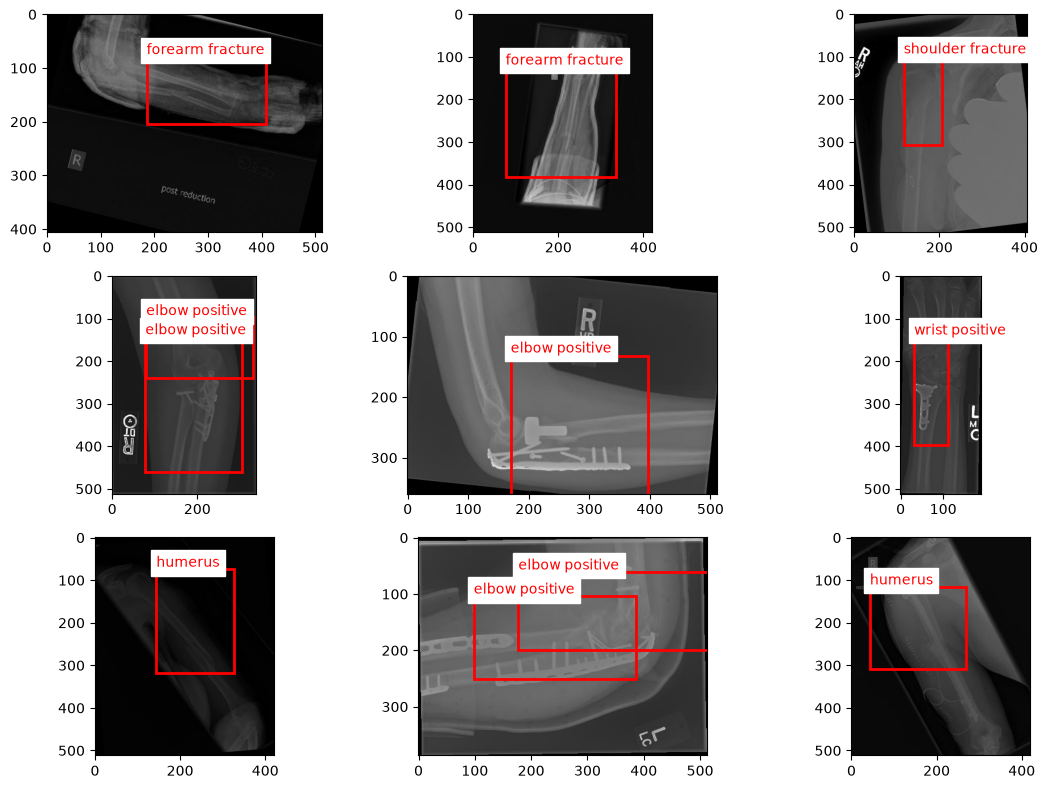

In [16]:
dataset_path = 'datasets/train'
display_random_images_with_labels(dataset_path, 9)